<h2><center>MNIST classification</center></h2>

In [88]:
# As a first step, we may want to switch to a GPU-acceperated VM
# In the menu: Runtime->Change runtime type->Hardware Accelerator->GPU.
#
# This will thest if we have a GPU-equipped VM and return some useful system-level information
!nvidia-smi

# Which GNU/Linux distribution is installed on our VM ?
!lsb_release -a

# Which version of the Linux kernel our VM has ?
!uname -a

# How much free memory our VM has ?
!free -h

# Which storage facilities our VM has ?
!mount

# Which python version our VM has installed ?
!python --version

Tue Nov 17 15:21:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   68C    P0             32W /   70W |     197MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# Importing Torch and related libraries

In [89]:
# Importing Torch 2.x module
import torch, torchvision
print("Using Torch version " + str(torch.__version__))

Using Torch version 2.14.1+cu130


In [90]:
# Torchvision provides datasets and more for CV tasks
import torchvision
print("Using Torch version " + str(torchvision.__version__))

Using Torch version 0.29.1+cu130


In [91]:
# Thid is optional for experiment reproducibility
#torch.manual_seed(1)

# Loading and preparing the MNIST dataset

In [92]:
#These transforms actually perform scaling only
from torchvision.transforms import v2

# Defining the tranformations we want to apply to our dataset (0-1 normalization in this case)
transform = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True)
])

train_transform = v2.Compose([
    v2.ToImage(),
    v2.RandomHorizontalFlip(),
    v2.ToDtype(torch.float32, scale=True)
])

In [ ]:
# Loading into memory the datasets for training and testing applying scaling
from torchvision import datasets

training_set = datasets.CIFAR10(
    './data',
    train=True,
    transform=train_transform,
    download=True
)

testing_set = datasets.CIFAR10(
    './data',
    train=False,
    transform=transform,
    download=True
)

  2%|▏         | 2.69M/170M [00:27<28:32, 98.0kB/s]

Creating a dataloder for the train and test datasets

In [ ]:
from torch.utils.data import DataLoader

# Batch sizes are usually multiples of 2 in the 16-32 range
batch_size = 32

# Creating one data loader for the training set and one for the test set
train_dataloader = DataLoader(training_set, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
test_dataloader = DataLoader(testing_set, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

# Inspecting the train images and labels...
for X, y in train_dataloader:
    print(f"Shape of train images [N, C, H, W]: {X.shape}")
    print(f"Shape of train labels: {y.shape} {y.dtype}")
    break

# ... and the test images and labels
for X, y in test_dataloader:
    print(f"Shape of train images [N, C, H, W]: {X.shape}")
    print(f"Shape of train labels: {y.shape} {y.dtype}")
    break

In [ ]:
# Let us visualize the first training sample in the batch using the Gnuplot library
from matplotlib import pyplot as plt

for X, y in train_dataloader:
    plt.imshow(X[0].permute(1, 2, 0))
    plt.title(y[0].item())
    break

# Defining the Model

In [ ]:
from torch import nn

# Define a LeNet300-like model
class MyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Conv2d(in_channels=3, out_channels=16, kernel_size=5, padding='same'),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5, padding='same'),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Dropout(0.5),
            nn.Linear(in_features=32 * 8 * 8, out_features=128),
            nn.ReLU(),
            nn.Linear(in_features=128, out_features=10),
            nn.LogSoftmax(1)
        )

    def forward(self, x):
        return self.model(x)

# This is the model instance that will be trained and tested
model = MyModel()

In [ ]:
# Getting hold of our GPU
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

# The model is bound to the GPU
model = model.to(device)
print(model)

# Instantiate one loss function and an optimizer

In [ ]:
#Since we have a LogSoftMax layer in our model, we use NLLLoss instead of CrossEntropyLoss
loss_fn = nn.NLLLoss()
# The optimizers module provides a number of optimization algorithms for updating
# a netwok parameters accoridng to the computed error gradints
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)

# Defnining the training function

In [ ]:
# This is where the actual training-testing happens
def train_epoch(dataloader, model, loss_fn, optimizer, lambda_reg=1e-4, verbose=False):
    size = len(dataloader.dataset)
    model.train()
    for batch, (X, y) in enumerate(dataloader):
        X, y = X.to(device), y.to(device)

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        l2_norm = sum(p.pow(2).sum() for p in model.parameters())
        loss += lambda_reg * l2_norm

        # Backpropagation
        loss.backward()
        optimizer.step()
        optimizer.zero_grad()

        if verbose and batch % 100 == 0:
            loss_val, current = loss.item(), (batch + 1) * len(X)
            print(f"loss: {loss_val:>7f}  [{current:>5d}/{size:>5d}]")

# Defining the testing function

In [ ]:
def eval_epoch(dataloader, model, loss_fn):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss, correct = 0, 0
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            preds = model(X)
            test_loss += loss_fn(preds, y).item()
            correct += (preds.argmax(1) == y).type(torch.float).sum().item()
    test_loss /= num_batches
    correct = 100 * (correct / size)
    return test_loss, correct
    #print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

#Main training loop - here is where learning happens

In [85]:
#For being able to plot the training history afterwards
history = {}
history['train_loss'] = []
history['train_acc'] = []
history['test_loss'] = []
history['test_acc'] = []

epochs = 20
for e in range(epochs):

    # Updating the model parameters for one epoch
    train_epoch(train_dataloader, model, loss_fn, optimizer)
    scheduler.step()

    # Testing on the train and testing sets to evaluate the model generalization ability
    train_loss, train_acc = eval_epoch(train_dataloader, model, loss_fn)
    test_loss, test_acc = eval_epoch(test_dataloader, model, loss_fn)
    print ('Epoch %d / %d lossTrain %.3f lossTest %.3f accuracyTrain %.3f accuracyTest %.3f' %(int(e)+1, epochs, train_loss, test_loss, train_acc, test_acc))

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['test_loss'].append(test_loss)
    history['test_acc'].append(test_acc)

print("Done!")

Epoch 1 / 20 lossTrain 0.418 lossTest 0.391 accuracyTrain 84.687 accuracyTest 85.490
Epoch 2 / 20 lossTrain 0.387 lossTest 0.383 accuracyTrain 85.225 accuracyTest 85.340
Epoch 3 / 20 lossTrain 0.339 lossTest 0.331 accuracyTrain 87.242 accuracyTest 87.650
Epoch 4 / 20 lossTrain 0.318 lossTest 0.310 accuracyTrain 88.015 accuracyTest 88.510
Epoch 5 / 20 lossTrain 0.295 lossTest 0.283 accuracyTrain 88.848 accuracyTest 89.540
Epoch 6 / 20 lossTrain 0.283 lossTest 0.282 accuracyTrain 89.513 accuracyTest 89.820
Epoch 7 / 20 lossTrain 0.279 lossTest 0.271 accuracyTrain 89.485 accuracyTest 89.940
Epoch 8 / 20 lossTrain 0.273 lossTest 0.274 accuracyTrain 90.005 accuracyTest 89.800
Epoch 9 / 20 lossTrain 0.260 lossTest 0.261 accuracyTrain 90.397 accuracyTest 90.420
Epoch 10 / 20 lossTrain 0.248 lossTest 0.248 accuracyTrain 90.912 accuracyTest 90.800
Epoch 11 / 20 lossTrain 0.240 lossTest 0.246 accuracyTrain 91.272 accuracyTest 90.910
Epoch 12 / 20 lossTrain 0.236 lossTest 0.241 accuracyTrain 91.3

# Visualizing the network performance

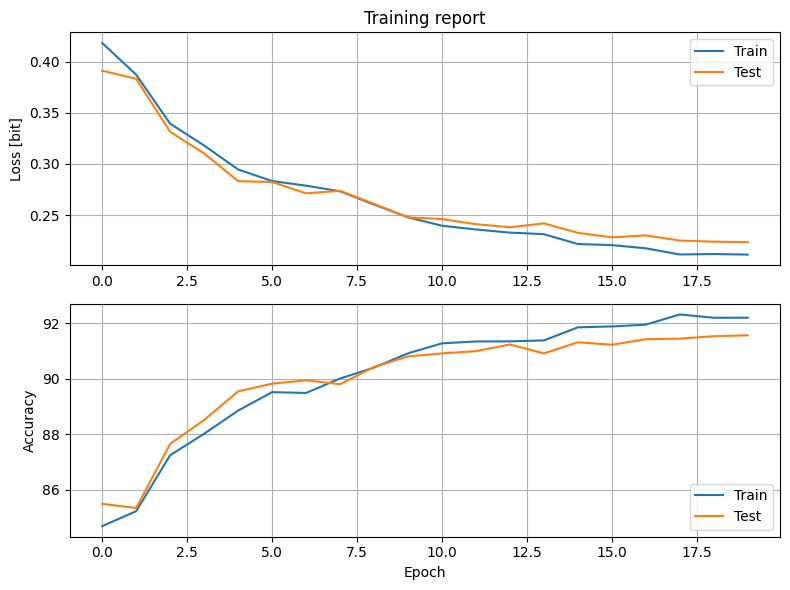

In [86]:
import matplotlib.pyplot as plt

_, axes = plt.subplots(nrows=2, ncols=1, figsize=(8, 6))

axes[0].grid()
axes[0].set_title('Training report')
axes[0].plot(history['train_loss'])
axes[0].plot(history['test_loss'])
axes[0].set_ylabel('Loss [bit]')
axes[0].legend(['Train', 'Test'], loc='upper right')

axes[1].grid()
axes[1].plot(history['train_acc'])
axes[1].plot(history['test_acc'])
axes[1].set_ylabel('Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].legend(['Train', 'Test'], loc='lower right')

plt.tight_layout()
plt.show()

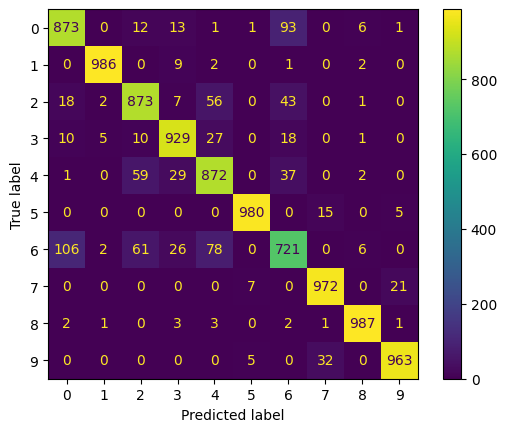

In [87]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_labels, all_predictions = [], []
model.eval()
with torch.no_grad():
    for imgs, labels in test_dataloader:
        all_labels.append(labels)
        imgs = imgs.to(device)
        out = model(imgs)
        all_predictions.append(out.cpu())

all_labels = torch.cat(all_labels, dim=0)
all_predictions = torch.cat(all_predictions, dim=0)

cm = confusion_matrix(all_labels, all_predictions.data.max(1, keepdim=True)[1])
ConfusionMatrixDisplay(cm).plot()
plt.show()